Trying to predict chance of 3rd down conversion

Imports

In [37]:
import pandas as pd
import nfl_data_py as nfl
import math
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance

In [24]:
def displaystats(predictions, actual):
    cm = confusion_matrix(actual, predictions)
    print(cm)
    accuracy = accuracy_score(actual, predictions)
    print(accuracy)

In [5]:
years = [2020]
alldata = nfl.import_pbp_data(years)
print(alldata.shape)

2020 done.
Downcasting floats.
(47705, 391)


In [6]:
thirddowns = alldata[alldata["down"] == 3].copy()
print(thirddowns.shape)
exploration_df = pd.DataFrame({"Data Type": thirddowns.dtypes,"Sample Value": thirddowns.iloc[0]})
print(exploration_df.to_string())

(7439, 391)
                                     Data Type                                                                                                                         Sample Value
play_id                                float32                                                                                                                                165.0
game_id                                 object                                                                                                                       2020_01_ARI_SF
old_game_id_x                           object                                                                                                                           2020091311
home_team                               object                                                                                                                                   SF
away_team                               object                                          

In [7]:
thirddowns = thirddowns.dropna(subset=["third_down_converted"])
thirddowns["converted"] = thirddowns["third_down_converted"].astype(int)
print(thirddowns["converted"].value_counts(normalize = True))

converted
0    0.616887
1    0.383113
Name: proportion, dtype: float64


In [54]:
# features = ["yardline_100", "ydstogo", "game_seconds_remaining", "score_differential", "no_huddle", "shotgun", "posteam_timeouts_remaining", "defteam_timeouts_remaining"]
features = ["ydstogo"]
data = thirddowns[features + ["converted"]].dropna()
print(data.head(4))

    ydstogo  converted
6      14.0          0
13     20.0          0
20      7.0          0
24      5.0          0


In [55]:
x = data[features]
y = data["converted"]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=.2)

In [56]:
model = LogisticRegression()
model.fit(x_train, y_train)
predictions = model.predict(x_test)
accuracy = accuracy_score(y_test, predictions)
print(accuracy)

0.6742934051144011


In [57]:
cm = confusion_matrix(y_test, predictions)
print(cm)

[[721 176]
 [308 281]]


In [58]:
probs = model.predict_proba(x_test)[:,1]
results = x_test.copy()
results["actual"] = y_test
results["predicted prob"] = probs
print(results.head(10))

       ydstogo  actual  predicted prob
46537      3.0       0        0.516233
43735     19.0       0        0.064610
34167     12.0       0        0.186196
37343      3.0       1        0.516233
7149       5.0       1        0.431130
40297      4.0       1        0.473489
12067      2.0       0        0.558740
19961     18.0       0        0.075753
43322      2.0       0        0.558740
36834      5.0       0        0.431130


In [59]:
probs = model.predict_proba(x_test)[:,1]
predictions = (probs >= .6).astype(int)
cm = confusion_matrix(y_test, predictions)
print(cm)
accuracy = accuracy_score(y_test, predictions)
print(accuracy)

[[835  62]
 [461 128]]
0.6480484522207268


In [60]:
for depth in range(1, 11):   
    dtmodel = DecisionTreeClassifier(max_depth=depth, random_state=3)
    dtmodel.fit(x_train, y_train)
    predictions = dtmodel.predict(x_test)
    print(f"\n Testing depth {depth}")
    print(f"training accuracy {dtmodel.score(x_train, y_train)}")
    print(f"testing accuracy {dtmodel.score(x_test, y_test)}")
    displaystats(predictions, y_test)


 Testing depth 1
training accuracy 0.6202020202020202
testing accuracy 0.6036339165545087
[[897   0]
 [589   0]]
0.6036339165545087

 Testing depth 2
training accuracy 0.6653198653198653
testing accuracy 0.6608344549125168
[[778 119]
 [385 204]]
0.6608344549125168

 Testing depth 3
training accuracy 0.6658249158249159
testing accuracy 0.6742934051144011
[[721 176]
 [308 281]]
0.6742934051144011

 Testing depth 4
training accuracy 0.6658249158249159
testing accuracy 0.6742934051144011
[[721 176]
 [308 281]]
0.6742934051144011

 Testing depth 5
training accuracy 0.6658249158249159
testing accuracy 0.6742934051144011
[[721 176]
 [308 281]]
0.6742934051144011

 Testing depth 6
training accuracy 0.6658249158249159
testing accuracy 0.6742934051144011
[[721 176]
 [308 281]]
0.6742934051144011

 Testing depth 7
training accuracy 0.6658249158249159
testing accuracy 0.6742934051144011
[[721 176]
 [308 281]]
0.6742934051144011

 Testing depth 8
training accuracy 0.6658249158249159
testing accura

In [46]:
conversionbyyardstogo = (thirddowns.groupby("ydstogo")["converted"].mean())
print(conversionbyyardstogo.head(20))

ydstogo
1.0     0.654977
2.0     0.559578
3.0     0.519135
4.0     0.422492
5.0     0.394366
6.0     0.395765
7.0     0.347754
8.0     0.310658
9.0     0.256659
10.0    0.266768
11.0    0.273148
12.0    0.133005
13.0    0.153846
14.0    0.166667
15.0    0.166667
16.0    0.121951
17.0    0.092308
18.0    0.109589
19.0    0.050000
20.0    0.090909
Name: converted, dtype: float64


In [47]:
def viewconversionbymetric(metric):
    conversionbymetric = (thirddowns.groupby(metric)["converted"].mean())
    conversionbymetric.head(20).plot(kind="bar", figsize = (10, 10))
    plt.title(f"Third down conversion by {metric}")
    plt.xlabel(metric)
    plt.ylabel("Conversion Rate")
    plt.show()

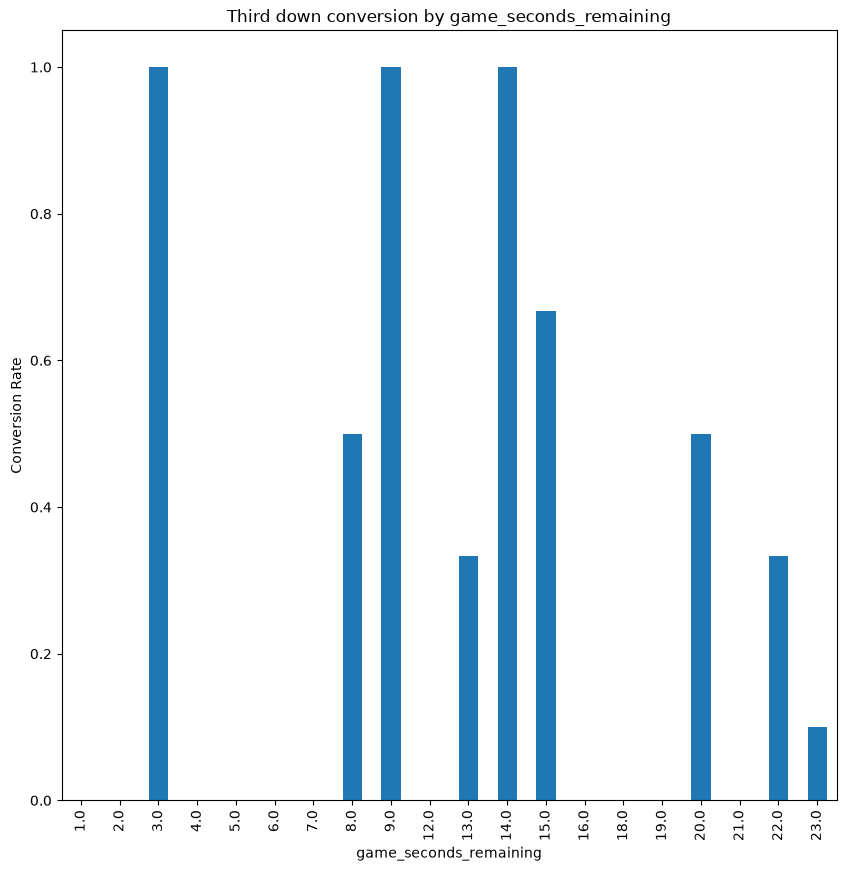

In [48]:
metric = "game_seconds_remaining"
viewconversionbymetric(metric)

   feature  importance
0  ydstogo    0.135397


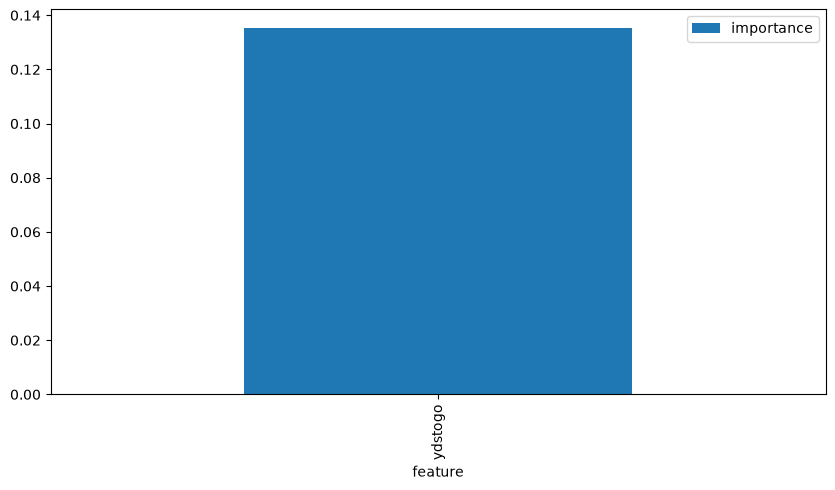

In [61]:
importance = permutation_importance(model, x_test, y_test, random_state=3)
featureimportance = pd.DataFrame({"feature": features, "importance": importance.importances_mean})
featureimportance = featureimportance.sort_values("importance", ascending=False)
print(featureimportance)
featureimportance.plot(x = "feature", y = "importance", kind = "bar", figsize = (10, 5))
plt.show()